# 01 – Načtení snímků, barevné modely a histogramy

**Cíl kroku:** poznat naše data  

**Data:** `data/sample/1.jpg` (11 mincí na černé podložce), `data/sample/2.jpg` (20 Kč + 5 Kč, podložka s prachem).

In [4]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Aby šel importovat náš balíček src/coins i při spuštění z notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from coins.io import load_rgb, show_images, SAMPLE_DIR

## 1. Načtení snímku a jeho reprezentace

1.jpg: shape=(1325, 994, 3), dtype=uint8, min=0, max=255, velikost v paměti=4.0 MB
2.jpg: shape=(1325, 994, 3), dtype=uint8, min=0, max=255, velikost v paměti=4.0 MB


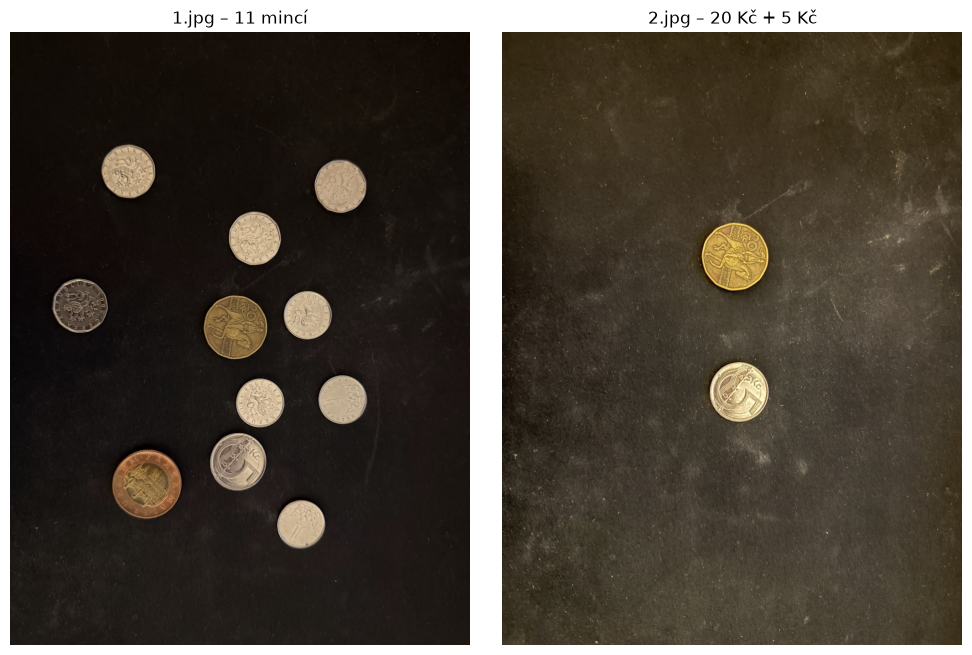

In [2]:
img1 = load_rgb(SAMPLE_DIR / "1.jpg")
img2 = load_rgb(SAMPLE_DIR / "2.jpg")

for name, img in [("1.jpg", img1), ("2.jpg", img2)]:
    print(f"{name}: shape={img.shape}, dtype={img.dtype}, min={img.min()}, max={img.max()}, "
          f"velikost v paměti={img.nbytes / 1e6:.1f} MB")

show_images([img1, img2], ["1.jpg – 11 mincí", "2.jpg – 20 Kč + 5 Kč"])

Pro výpočty převádíme na `float32` v rozsahu 0–1, aby nedocházelo k přetečení (u `uint8` je 200 + 100 = 44, ne 300).

## 2. Šedotónový snímek a jeho histogram

Histogram = počet pixelů pro každou úroveň jasu.

Mince tvoří jen malou část snímku (pod 10 % pixelů), proto histogram kreslíme i v **logaritmickém měřítku**,
jinak kopec mincí vedle obrovského kopce pozadí nebude vidět.

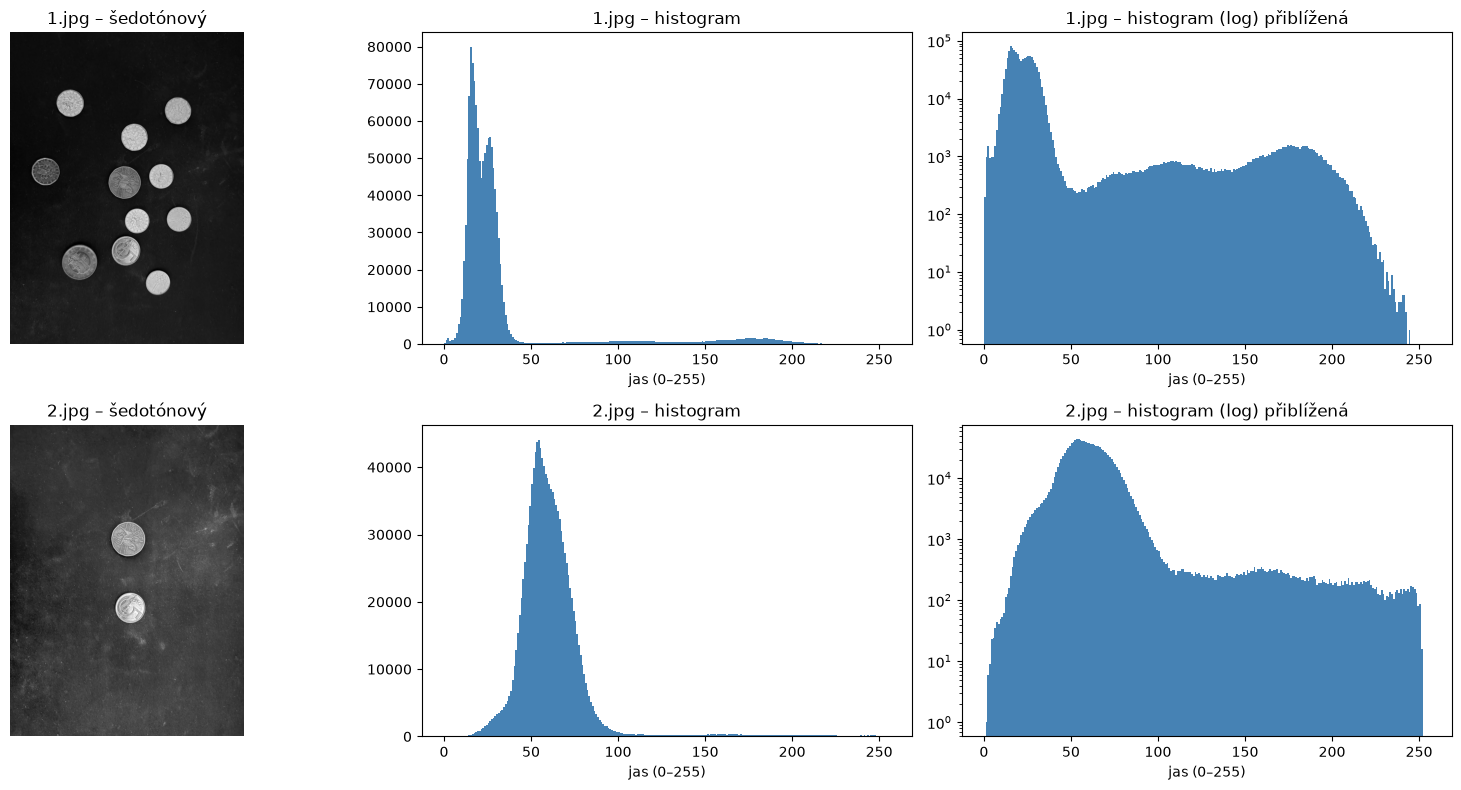

In [7]:
#Převedeme si to na šedou
gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, (name, g) in enumerate([("1.jpg", gray1), ("2.jpg", gray2)]):
    axes[row, 0].imshow(g, cmap="gray"); axes[row, 0].set_title(f"{name} – šedotónový"); axes[row, 0].axis("off")
    axes[row, 1].hist(g.ravel(), bins=256, range=(0, 256), color="steelblue")
    axes[row, 1].set_title(f"{name} – histogram"); axes[row, 1].set_xlabel("jas (0–255)")
    axes[row, 2].hist(g.ravel(), bins=256, range=(0, 256), color="steelblue", log=True)
    axes[row, 2].set_title(f"{name} – histogram (log) přiblížená"); axes[row, 2].set_xlabel("jas (0–255)")
plt.tight_layout()
plt.show()
#VLEVO JE černá v pravo je bíla!

## 3. Barevný model HSV

RGB míchá barvu a jas dohromady. **HSV** je odděluje
- **H (Hue)** – odstín
- **S (Saturation)** – sytost
- **V (Value)** – jas

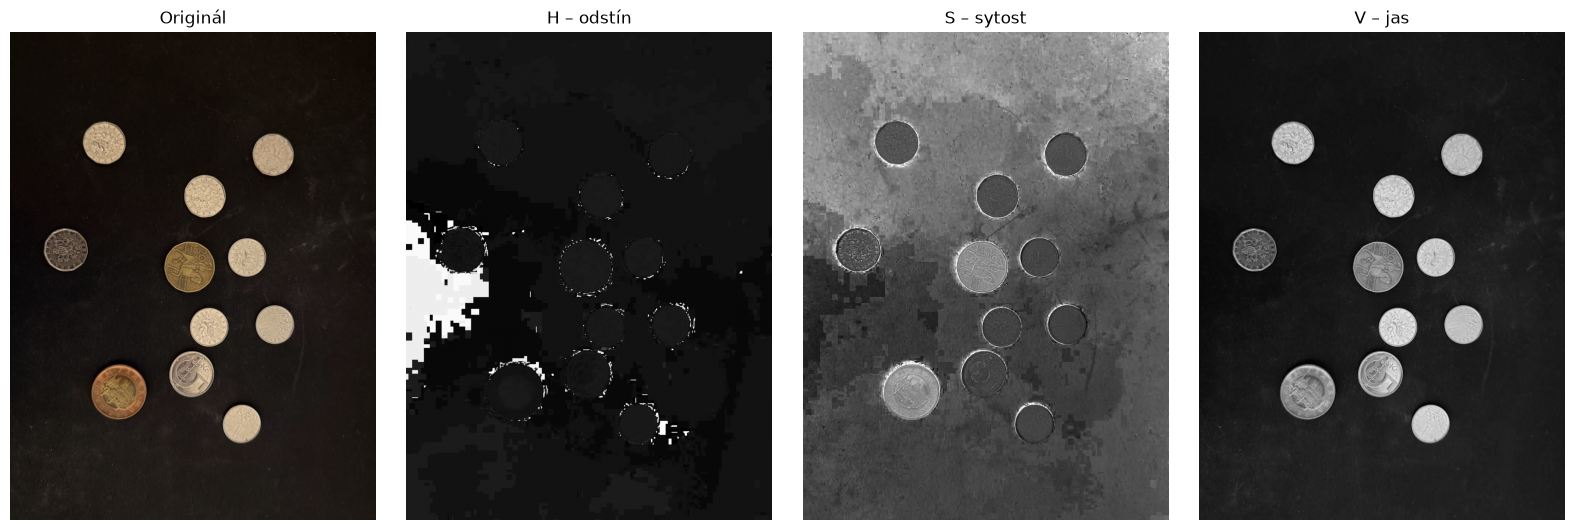

In [10]:
hsv1 = cv2.cvtColor(img1, cv2.COLOR_RGB2HSV)
h1, s1, v1 = cv2.split(hsv1)

show_images([img1, h1, s1, v1], ["Originál", "H – odstín", "S – sytost", "V – jas"], cols=4, size=4)
#chceme zjistit, který pro nás bude nejlepší kanal

oblast               H      S      V
pozadí            14.2  147.9   16.9
1 Kč              17.9   65.1  191.2
2 Kč              17.1   84.3  181.3
5 Kč              13.1   70.8  144.0
20 Kč             19.1  142.8  149.0
50 Kč (střed)     17.6  141.6  138.8


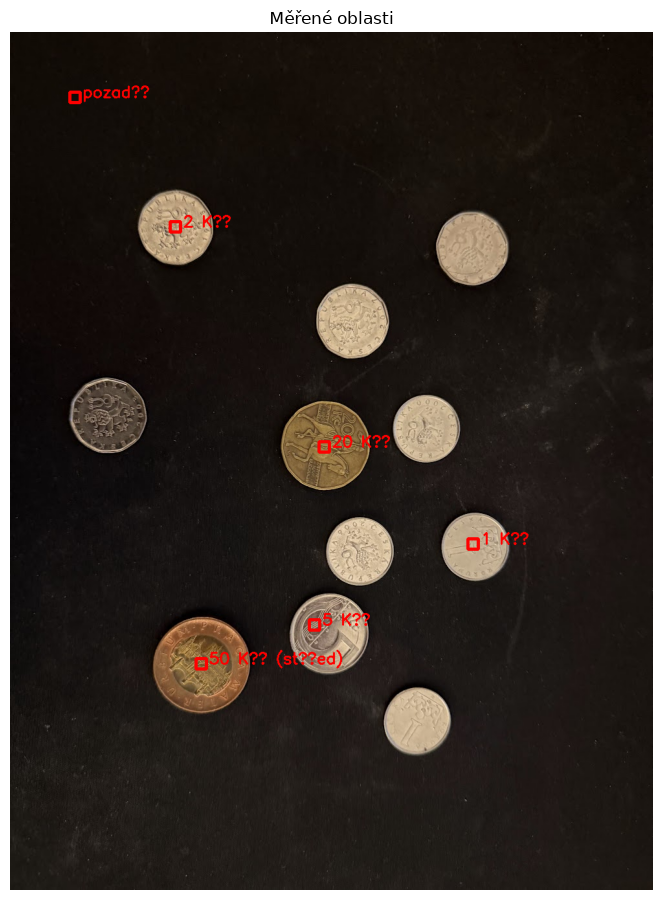

In [20]:
def roi_mean(hsv, x, y, r=8):
    patch = hsv[y - r:y + r, x - r:x + r].reshape(-1, 3).astype(np.float32)
    return patch.mean(axis=0)

# (x, y) středy oblastí v 1.jpg. Odečteno z obrázku ručně
rois_1 = {
    "pozadí": (100, 100),
    "1 Kč": (715, 790),
    "2 Kč": (255, 300),
    "5 Kč": (470, 915),
    "20 Kč": (485, 640),
    "50 Kč (střed)": (295, 975),
}

print(f"{'oblast':15s} {'H':>6s} {'S':>6s} {'V':>6s}")
for name, (x, y) in rois_1.items():
    h, s, v = roi_mean(hsv1, x, y)
    print(f"{name:15s} {h:6.1f} {s:6.1f} {v:6.1f}")

vis = img1.copy()
for name, (x, y) in rois_1.items():
    cv2.rectangle(vis, (x - 8, y - 8), (x + 8, y + 8), (255, 0, 0), 3)
    cv2.putText(vis, name, (x + 12, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
show_images([vis], ["Měřené oblasti"], size=7)
# Cíl zda mince půjdou rozpoznat

## 4. Roztažení a ekvalizace histogramu
# Pokus o zvětšení kontrastu

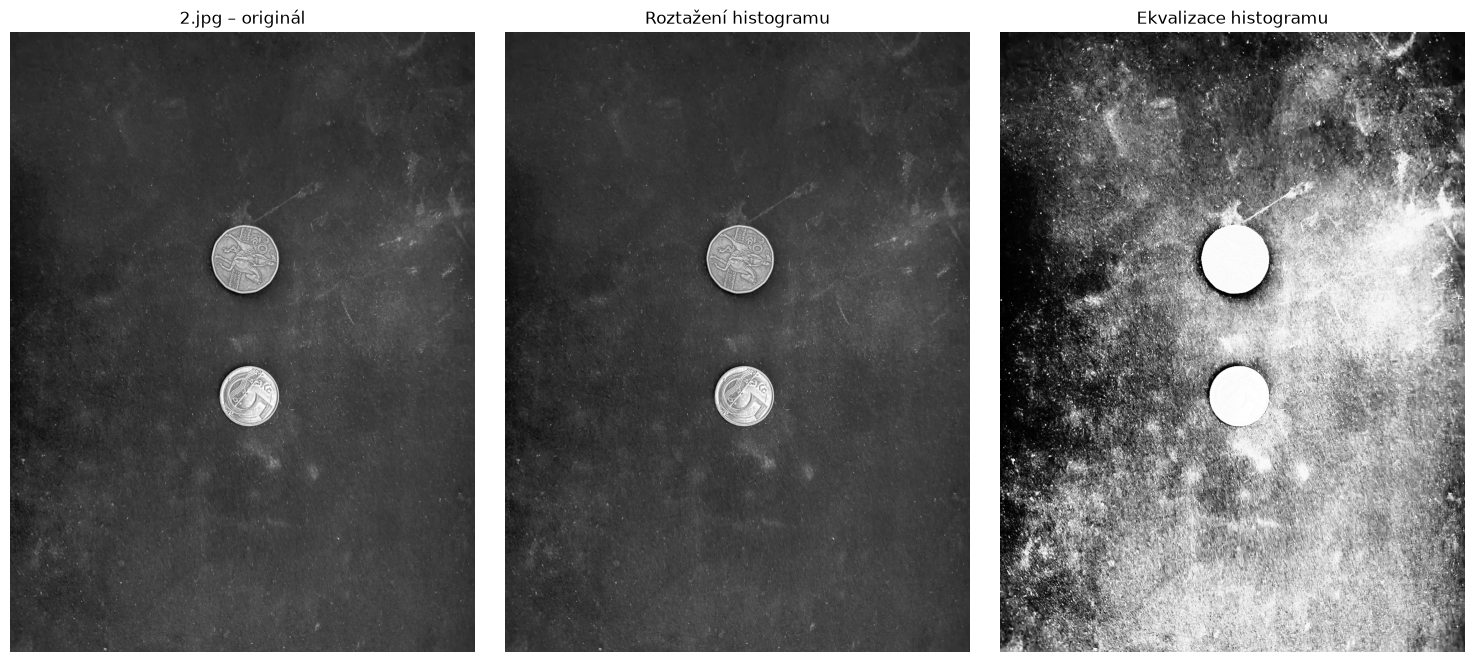

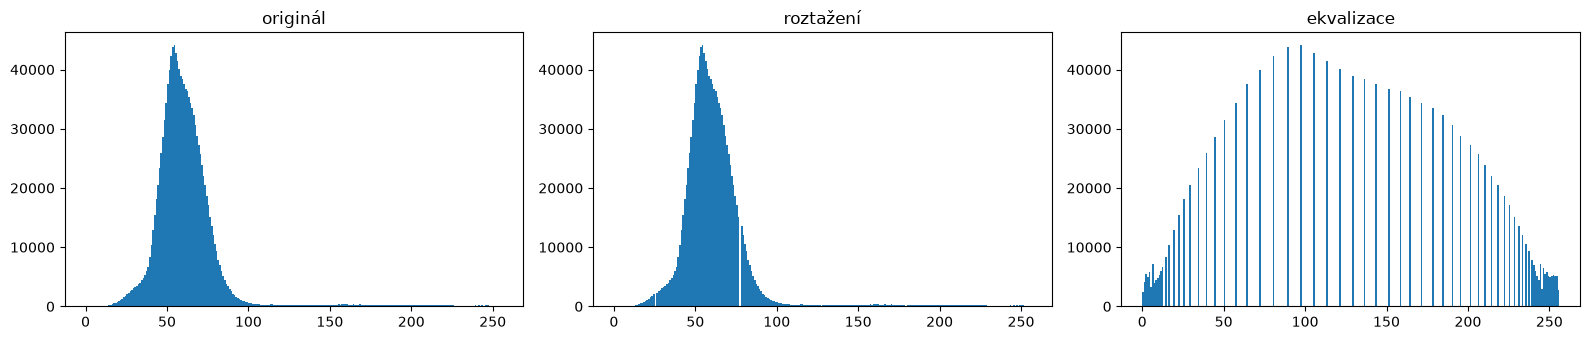

In [22]:
stretched2 = cv2.normalize(gray2, None, 0, 255, cv2.NORM_MINMAX)
equalized2 = cv2.equalizeHist(gray2)

show_images([gray2, stretched2, equalized2],
            ["2.jpg – originál", "Roztažení histogramu", "Ekvalizace histogramu"], cols=3, size=5)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, g, t in zip(axes, [gray2, stretched2, equalized2], ["originál", "roztažení", "ekvalizace"]):
    ax.hist(g.ravel(), bins=256, range=(0, 256)); ax.set_title(t)
plt.tight_layout()
plt.show()